1. La receta común.

In [2]:
%run 1_home.ipynb

2. La serie del IPC (INDEC, nivel general nacional, base dic-2016=100) y la función que deflacta. Mes de referencia: enero 2019.

In [3]:
# IPC nacional, INDEC via datos.gob.ar (serie 148.3_INIVELNAL_DICI_M_26)
IPC = {
    201901: 189.6101, 201902: 196.7501, 201903: 205.9571, 201904: 213.0517,
    201905: 219.5691, 201906: 225.5370, 201907: 230.4940, 201908: 239.6077,
    201909: 253.7102, 201910: 262.0661, 201911: 273.2158, 201912: 283.4442,
}
MES_REFERENCIA = 201901

def columnas_monetarias(df):
    return [c for c in df.columns
            if c.startswith("m") or c.startswith("Master_m") or c.startswith("Visa_m")]

def deflactar(df, indice, mes_referencia=MES_REFERENCIA, columnas=None):
    """monto / indice del mes * indice del mes de referencia"""
    out = df.copy()
    columnas = columnas or columnas_monetarias(df)
    factor = df.foto_mes.map(indice).astype("float32")
    out[columnas] = out[columnas].astype("float32").div(factor, axis=0) * indice[mes_referencia]
    return out

print(len(columnas_monetarias(cargar_datos().head(1))), "columnas monetarias")

73 columnas monetarias


3. Deflactar y recién después armar lags y deltas. Este es el orden que importa: las históricas se calculan sobre valores reales.

In [4]:
df = cargar_datos()
df_ipc = deflactar(df, IPC)
datos, features = agregar_lags_deltas(df_ipc)
print(datos.shape, len(features))

(1563565, 763) 760


4. BO. Estudio aparte del baseline, porque es otro dataset.

In [5]:
import os, shutil

ESTUDIO_LOCAL = "/home/ds/datasets/optuna_ipc.db"
ESTUDIO_BUCKET = "/home/ds/buckets/b1/optuna_ipc.db"

if not os.path.exists(ESTUDIO_LOCAL) and os.path.exists(ESTUDIO_BUCKET):
    shutil.copy(ESTUDIO_BUCKET, ESTUDIO_LOCAL)

estudio_ipc = optimizar(datos, features, "deflactado_ipc",
                        storage=f"sqlite:///{ESTUDIO_LOCAL}")

shutil.copy(ESTUDIO_LOCAL, ESTUDIO_BUCKET)

[I 2026-11-15 07:49:01,075] Using an existing study with `study_name='deflactado_ipc'` instead of creating a new one.


[deflactado_ipc] trials completos: 3, faltan: 47


  0%|          | 0/47 [00:00<?, ?it/s]

[I 2026-11-15 07:49:49,008] Trial 5 finished with value: 0.9202466358030028 and parameters: {'num_leaves': 174, 'learning_rate': 0.21119729380744556, 'min_data_in_leaf': 3555, 'feature_fraction': 0.4261986361098682, 'bagging_fraction': 0.47360212107881416}. Best is trial 2 with value: 0.928924252124958.
[I 2026-11-15 07:50:12,220] Trial 6 finished with value: 0.9182796847577234 and parameters: {'num_leaves': 27, 'learning_rate': 0.20936112014418523, 'min_data_in_leaf': 1107, 'feature_fraction': 0.9093362456134209, 'bagging_fraction': 0.97222629698359}. Best is trial 2 with value: 0.928924252124958.
[I 2026-11-15 07:50:53,977] Trial 7 finished with value: 0.928924252124958 and parameters: {'num_leaves': 146, 'learning_rate': 0.11949484675078148, 'min_data_in_leaf': 7829, 'feature_fraction': 0.9995891079559249, 'bagging_fraction': 0.6947702612827709}. Best is trial 2 with value: 0.928924252124958.
[I 2026-11-15 07:51:49,653] Trial 8 finished with value: 0.9273173453708257 and parameters:

'/home/ds/buckets/b1/optuna_ipc.db'

5. Las mismas 5 semillas.

In [9]:
res_ipc, curvas_ipc, probas_ipc = correr_semillas(datos, features, estudio_ipc)
res_ipc.to_csv("/home/ds/buckets/b1/ipc_5semillas.csv", index=False)
res_ipc

  semilla 100129: $286,247,500 con 3,831 envios (3015s)
  semilla 100183: $284,707,500 con 4,047 envios (4996s)
  semilla 100151: $287,842,500 con 5,453 envios (3949s)
  semilla 500041: $286,852,500 con 5,569 envios (5002s)
  semilla 900007: $286,440,000 con 4,064 envios (5006s)
media $286,418,000  desvio $1,137,251


,semilla,ganancia,envios
0,100129,286247500.0,3831
1,100183,284707500.0,4047
2,100151,287842500.0,5453
3,500041,286852500.0,5569
4,900007,286440000.0,4064


6. La comparación contra el baseline.

In [7]:
res_base = pd.read_csv("/home/ds/buckets/b1/baseline_5semillas.csv")
comparar(res_base, res_ipc, "nominal", "deflactado IPC")

nominal: $289,872,000   deflactado IPC: $286,418,000
diferencia media: $-3,454,000  (-1.19%)
gana el experimento en 0 de 5 semillas
Wilcoxon necesita al menos 6 pares para dar un p confiable


array([-10065000.,   -137500.,   -330000.,   -165000.,  -6572500.])

7. Los dos juntos en un boxplot.

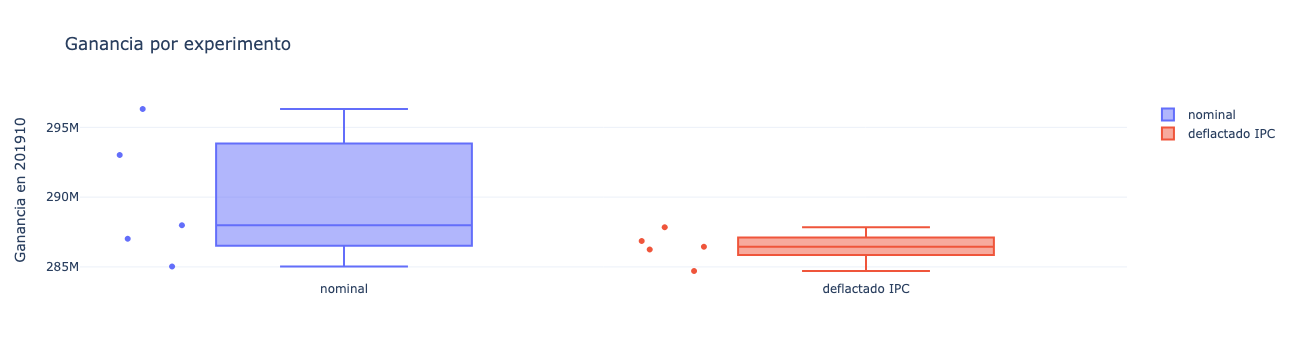

In [8]:
grafico_comparacion({"nominal": res_base, "deflactado IPC": res_ipc}).show()